# Bonus : le train face à l'avion

Liaisons aériennes intérieures (DGAC) et facteurs d'émission (ADEME, Base Carbone), en 2017 et 2023.

In [1]:
import os
import sys

import yaml
import geopandas as gpd
import pandas as pd

# on se place à la racine du projet
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

import src.visualisation as vis

liaisons = pd.read_parquet("data/clean/base_finale/base_finale_liaisons_co2.parquet")
os.makedirs("figures", exist_ok=True)

## Le CO2 de l'avion comparé au TGV

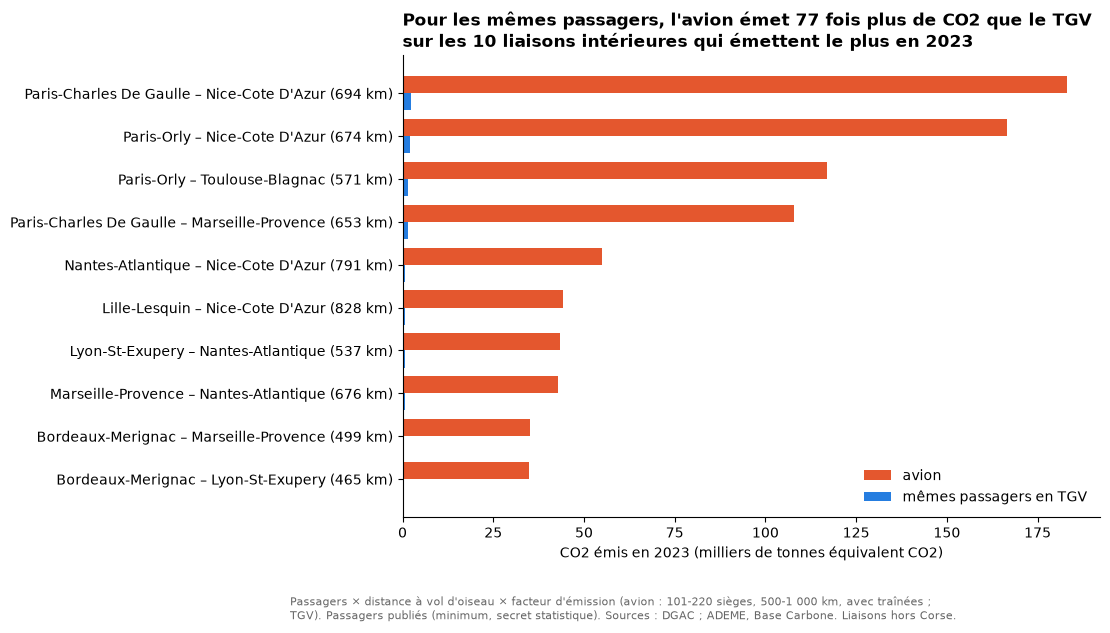

In [2]:
annee = config["annee_fin"]
hors_corse = liaisons.dropna(subset=[f"co2_tgv_t_{annee}"])
rapport = hors_corse[f"co2_avion_t_{annee}"].sum() / hors_corse[f"co2_tgv_t_{annee}"].sum()
titre = (f"Pour les mêmes passagers, l'avion émet {rapport:.0f} fois plus de CO2 que le TGV\n"
         f"sur les 10 liaisons intérieures qui émettent le plus en {annee}")
vis.plot_co2_avion_tgv(liaisons, annee, 10, titre, "figures/bonus_co2_avion_tgv.png");

Les quatre liaisons qui émettent le plus partent de Paris vers Nice, Toulouse et Marseille, où le TGV existe :
reporter ces passagers sur le train diviserait leurs émissions par environ 77. L'écart est sous-estimé, car le
train fait en réalité plus de kilomètres que l'avion.

## L'évolution des passagers aériens selon la distance

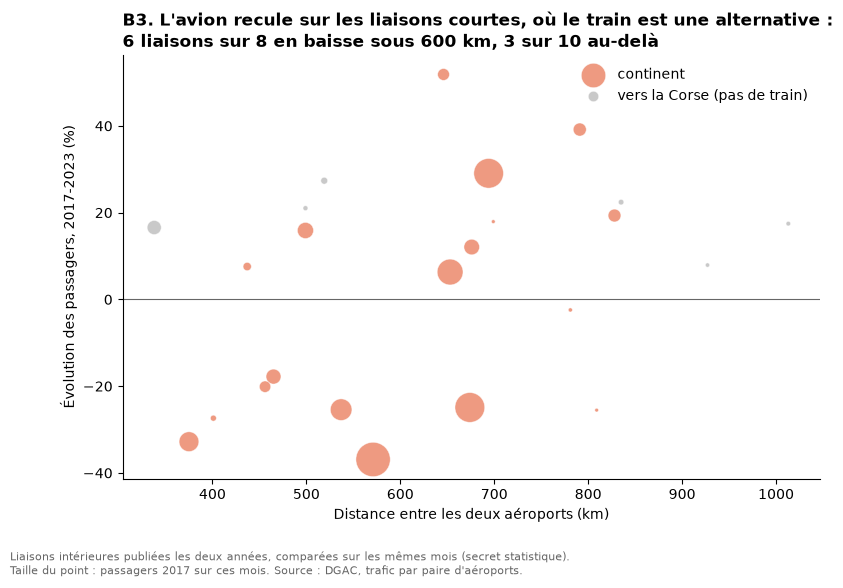

In [3]:
communs = liaisons[liaisons["mois_communs"] > 0]
continent = communs[~(communs["code_oaci_1"].str.startswith("LFK") | communs["code_oaci_2"].str.startswith("LFK"))]
baisse = continent["passagers_communs_2023"] < continent["passagers_communs_2017"]
courtes = continent["dist_km"] < 600
titre = (f"B3. L'avion recule sur les liaisons courtes, où le train est une alternative :\n"
         f"{baisse[courtes].sum()} liaisons sur {courtes.sum()} en baisse sous 600 km, "
         f"{baisse[~courtes].sum()} sur {(~courtes).sum()} au-delà")
vis.plot_avion_distance(liaisons, config["annee_debut"], config["annee_fin"], titre, "figures/bonus_B3_avion_distance.png");

Sur le continent, l'avion perd des passagers sur les liaisons de moins de 600 km (Orly – Toulouse −37 %,
Lyon – Toulouse −33 %), où le TGV ou l'Intercités sont compétitifs, et en gagne sur les longues liaisons
vers Nice ; vers la Corse, sans alternative ferroviaire, toutes les liaisons progressent.

## B2. Carte des liaisons aériennes intérieures

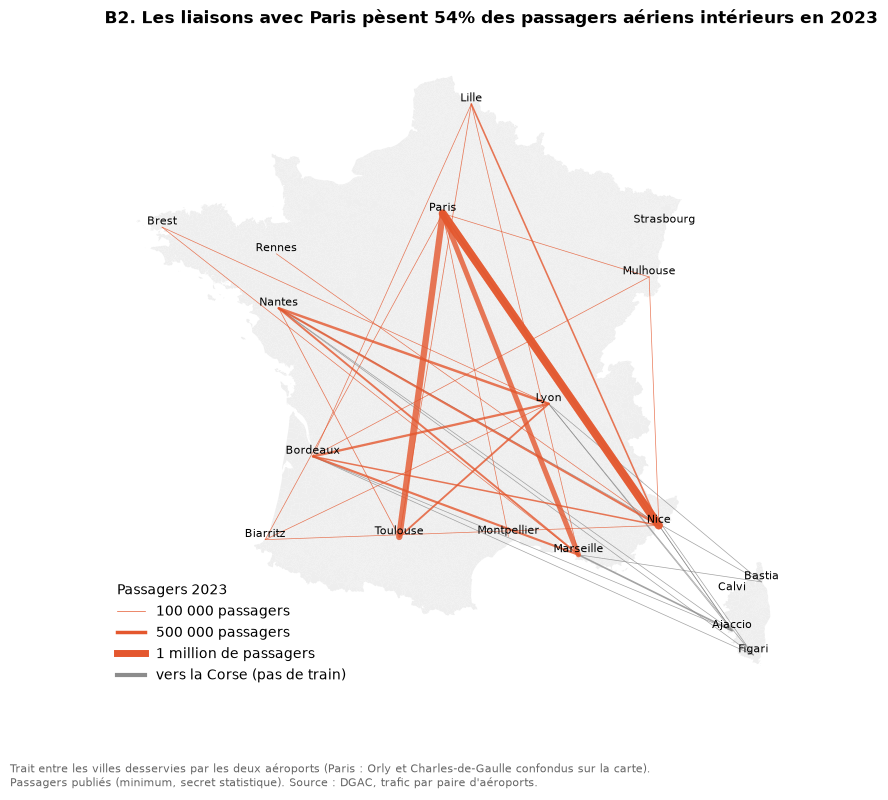

In [4]:
import yaml
with open("config.yaml") as f:
    config = yaml.safe_load(f)
villes = pd.DataFrame.from_dict(config["aeroports_villes"], orient="index").rename_axis("code_oaci").reset_index()
liaisons = pd.read_parquet("data/clean/base_finale/base_finale_liaisons_co2.parquet")
communes = gpd.read_parquet("data/clean/base_finale/base_finale_communes.parquet")
paris = liaisons["code_oaci_1"].isin(["LFPG", "LFPO"]) | liaisons["code_oaci_2"].isin(["LFPG", "LFPO"])
part_paris = liaisons.loc[paris, "passagers_2023"].sum() / liaisons["passagers_2023"].sum()
vis.map_liaisons(communes, villes, liaisons, 2023, f"B2. Les liaisons avec Paris pèsent {part_paris:.0%} des passagers aériens intérieurs en 2023", "output/B2_carte_liaisons.png")

Le trafic aérien intérieur reste centré sur Paris : les liaisons les plus épaisses partent de Paris vers Nice, Toulouse et Marseille, toutes à plus de 550 km, là où le TGV est le moins compétitif.
Les liaisons vers la Corse (en gris) n'ont aucune alternative ferroviaire ; ailleurs, les transversales comme Nantes–Lyon ou Bordeaux–Nice comblent l'absence de ligne directe en train.